# Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

### Collect data

In [2]:
import pandas as pd
from tqdm import tqdm
datacol = pd.read_csv('./data/benchmark_24-replicas.csv')
result_dirs = ['../../results/11714894_subsets', '../../results/11824789']
chunks = []
for _, dataset in tqdm(datacol.iterrows(), total=len(datacol)):
    for result_dir in result_dirs:
        statpath = os.path.join(result_dir, 'stats', dataset.path + '.csv')
        if os.path.exists(statpath):
            chunks.append(pd.read_csv(statpath))
statdata = pd.concat(chunks)
del chunks
# statdata.to_csv('./data/statdata.csv', index=False)
print('statdata successfully collected.')

100%|██████████| 1828/1828 [00:15<00:00, 114.32it/s]
statdata successfully collected.


In [3]:
# statdata = pd.read_csv('./data/statdata.csv')
statdata = statdata[statdata['ranking_method'] != 'Stability Selection']
print(statdata.shape)
statdata.head()

(751260, 11)


,cpu_time,feature_rank,ranking_method,replica_no,name,description,recall,precision,fpr,f1,auc
0,3.855204,4.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.333333,0.222222,0.500000,NaN
1,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,NaN
2,3.855204,5.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.250000,0.333333,0.400000,NaN
3,3.855204,3.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.500000,0.111111,0.666667,NaN
4,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,NaN


PR and ROC Curve

In [32]:
from tqdm import tqdm
import numpy as np

# compute means over several replicas by interpolation
def interpolate_metrics(replicas, metric_x, metric_y, roc=True):
    ys = []
    mean_x = np.linspace(0, 1, 100)
    for key, data in replicas.groupby([ 'replica_no' ]):
        x = data.sort_values(metric_x)[metric_x].values
        y = data.sort_values(metric_y)[metric_y].values
        interp_y = np.interp(mean_x, x, y)
        if roc:
            interp_y[0] = 0.0
        ys.append(interp_y)
    mean_y = np.mean(ys, axis=0)
    if roc:
        mean_y[-1] = 1.0
    auc = np.trapz(mean_y, mean_x)
    return mean_x, mean_y, auc

interpdata = []
for key, data in tqdm(statdata.groupby([ 'description', 'ranking_method' ])):
    description, ranking_method = key
    name = data['name'].values[0]
    fpr, tpr, roc_auc = interpolate_metrics(data, 'fpr', 'recall')
    recall, precision, pr_auc = interpolate_metrics(data, 'recall', 'precision', roc=False)
    
    interpdata.append(pd.DataFrame(data={
        'description': description,
        'multiline_description': description.replace(' [p=', '\n[p='),
        'name': name,
        'ranking_method': ranking_method,
        'fpr': fpr,
        'tpr': tpr,
        'recall': recall,
        'precision': precision,
        'pr_auc': pr_auc,
        'roc_auc': roc_auc
    }))
interpdata = pd.concat(interpdata)
interpdata.shape

100%|██████████| 418/418 [00:56<00:00,  7.36it/s]


(41800, 10)

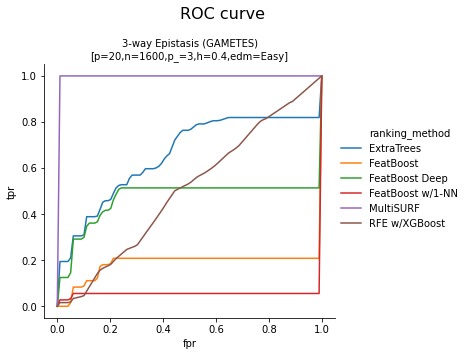

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt
g = sns.relplot(data=interpdata[interpdata['name'] == '3-way Epistasis (GAMETES)'],\
                x='fpr', y='tpr', hue='ranking_method',\
                col='multiline_description', kind='line',\
                estimator=None, col_wrap=1,\
                facet_kws={'sharex': False, 'sharey': False})
g.set_titles("{col_name}")
g.fig.suptitle("ROC curve", size=16)
g.fig.subplots_adjust(top=.82)

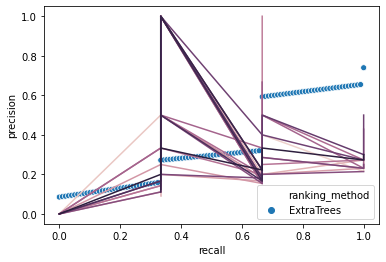

In [61]:
g = sns.lineplot(data=statdata[(statdata['name'] == '3-way Epistasis (GAMETES)') &\
                                (statdata['ranking_method'] == 'ExtraTrees')],\
                 x='recall', y='precision', hue='replica_no',\
                 estimator=None, units='replica_no', legend=False)
sns.scatterplot(data=interpdata[(interpdata['name'] == '3-way Epistasis (GAMETES)') &\
                                (interpdata['ranking_method'] == 'ExtraTrees')],\
                 x='recall', y='precision', hue='ranking_method')

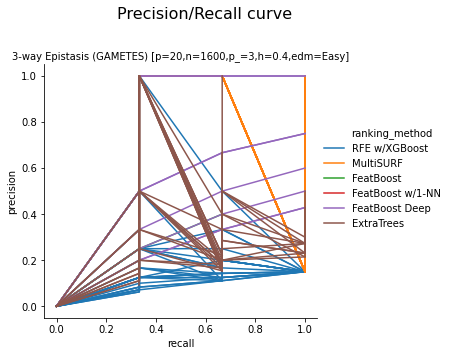

In [55]:
g = sns.relplot(data=statdata[statdata['name'] == '3-way Epistasis (GAMETES)'],\
                x='recall', y='precision', hue='ranking_method',\
                col='description', kind='line',\
                units='replica_no', estimator=None, col_wrap=1,\
                facet_kws={'sharex': False, 'sharey': False})
g.set_titles("{col_name}")
g.fig.suptitle("Precision/Recall curve", size=16)
g.fig.subplots_adjust(top=.82)

AUC scores

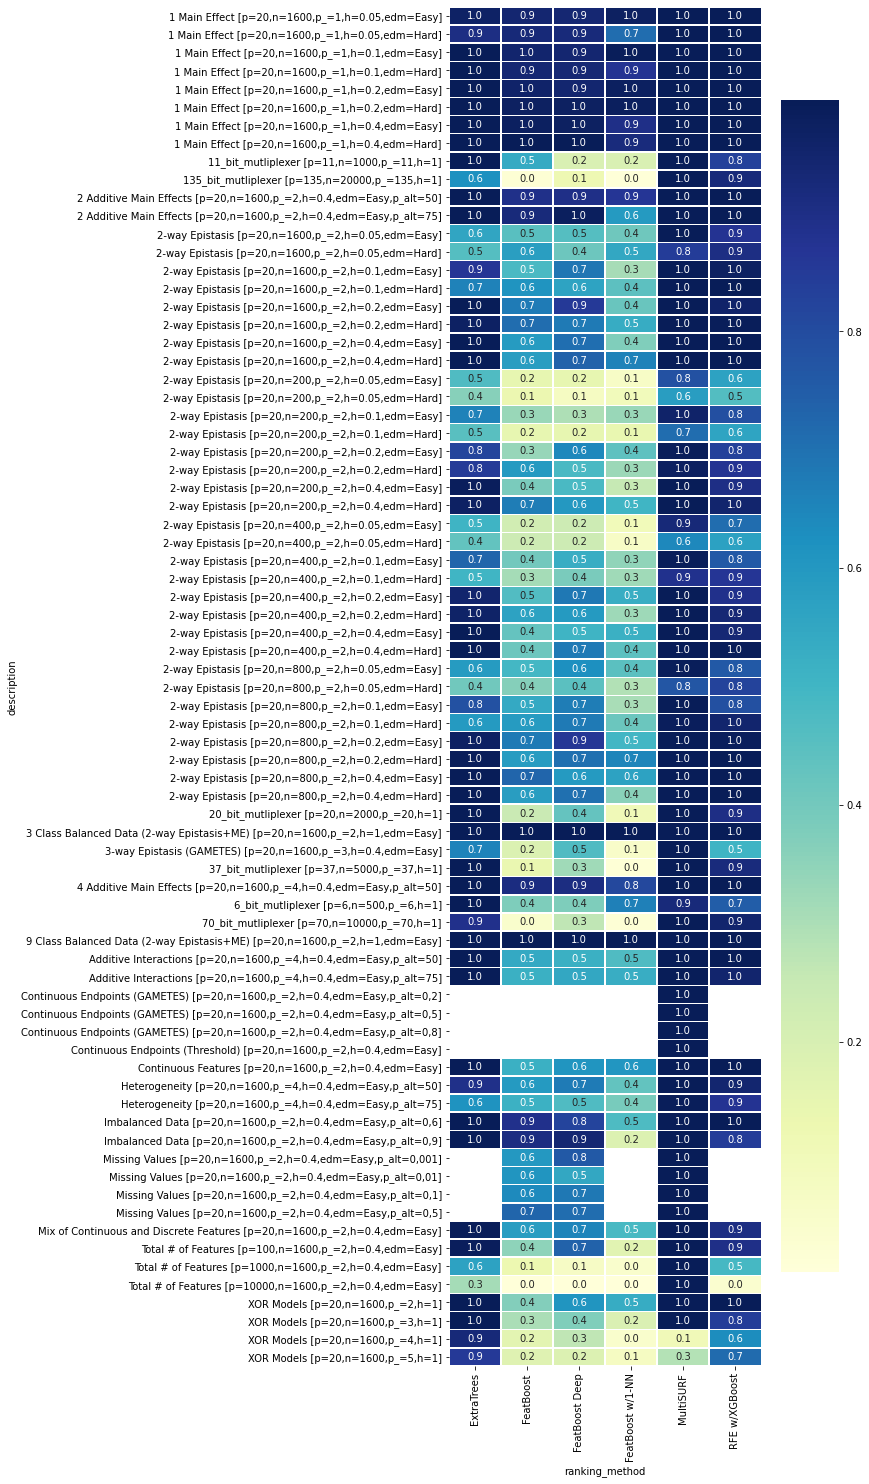

In [34]:
rectangular = pd.pivot_table(interpdata,\
    values='roc_auc',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(rectangular,\
    annot=True, fmt=".1f", linewidths=.5,\
    cmap="YlGnBu", yticklabels=True, ax=ax)

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

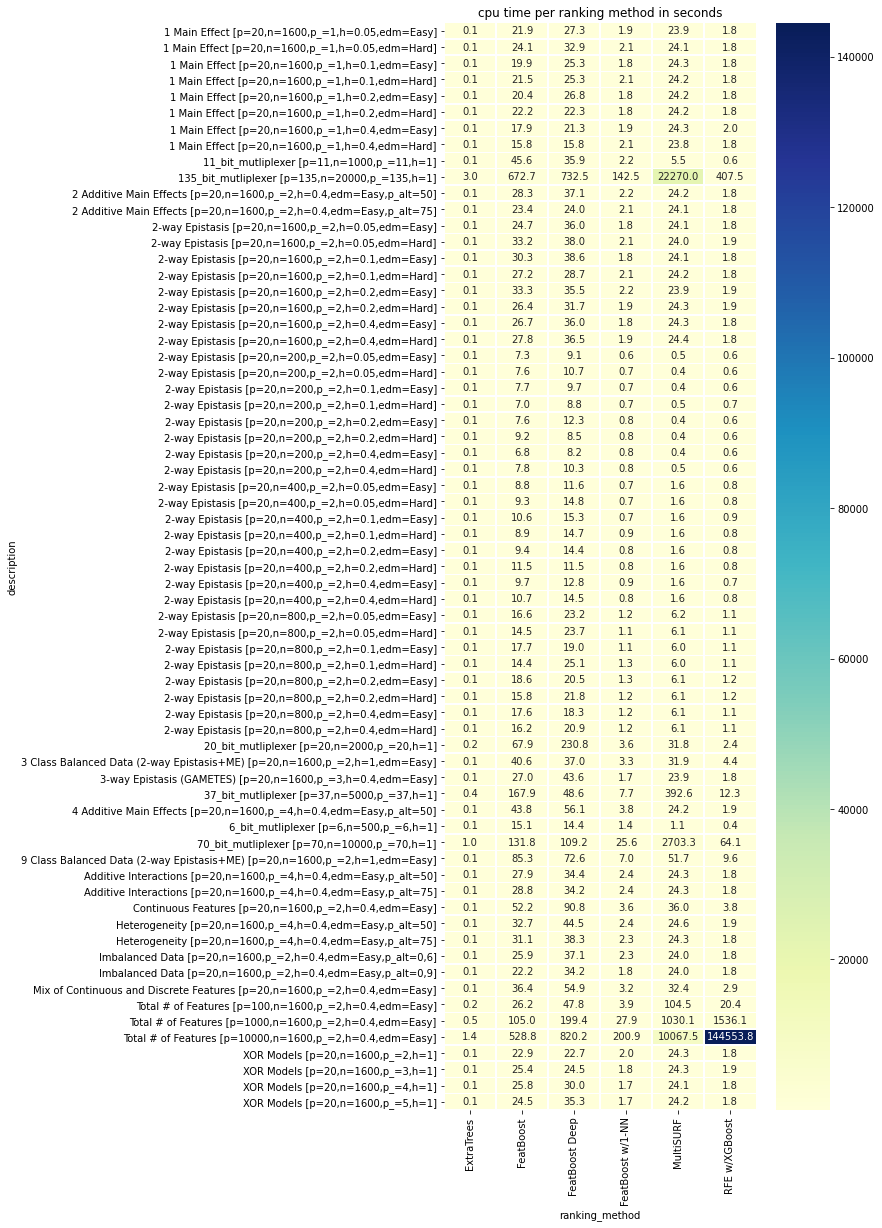

In [122]:
import seaborn as sns
import matplotlib.pyplot as plt
pivot = pd.pivot_table(subset,\
    values='cpu_time', index=['description'], columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 20))
ax = sns.heatmap(pivot, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('cpu time per ranking method in seconds')